- Look	at	the	data	and	identify	one	trend	or	anomaly	that	you	would	flag	to	the business.	Write	a	short	note	(half	a	page	to	one	page)	covering:	what	you	found,	the
evidence	from	the	data,	two	or	three	plausible	explanations,	and	what	you	would check	next	if	you	had	access	to	the	team.	We	are	more	interested	in	how	you	think than	in	a	“right”	answer.

In [1]:
# imports
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

customers = pd.read_csv("../data/customers.csv", parse_dates=["signup_date"])
payments = pd.read_csv("../data/payments.csv", parse_dates=["payment_date"])
rentals = pd.read_csv("../data/rentals.csv", parse_dates=["start_date", "end_date"])

In [2]:
print(customers.columns)
print(rentals.columns)
print(payments.columns)

Index(['customer_id', 'city', 'signup_date', 'channel'], dtype='object')
Index(['rental_id', 'customer_id', 'product_category', 'start_date',
       'end_date', 'monthly_rent', 'status'],
      dtype='object')
Index(['payment_id', 'rental_id', 'payment_date', 'amount', 'status'], dtype='object')


#### Main Analysis

In [3]:
# merging rentals with customers
df = rentals.merge(customers, on="customer_id", how="left")
df["start_month"] = df["start_date"].dt.to_period("M")

In [4]:
# 3rd jan - 12 oct so here these months will give partial data so i removed them below
print(df["start_date"].min())
print(df["start_date"].max())

2026-01-03 00:00:00
2026-10-12 00:00:00


In [5]:
# including only feb - sep and removing partial months
df = df[(df["start_month"] > "2026-01") & (df["start_month"] < "2026-10")]
print(df["start_month"].min())
print(df["start_month"].max())

2026-02
2026-09


In [6]:
# # sanity check
# df.duplicated().sum()
# df.isnull().sum()

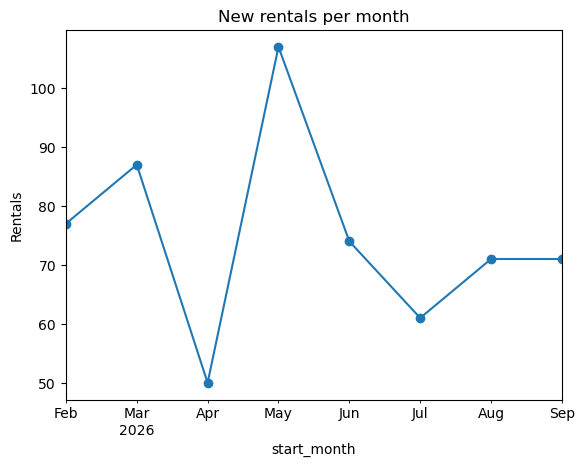

In [7]:
monthly = df.groupby("start_month").size()

monthly.plot(marker="o", title="New rentals per month")
plt.ylabel("Rentals")
plt.show()

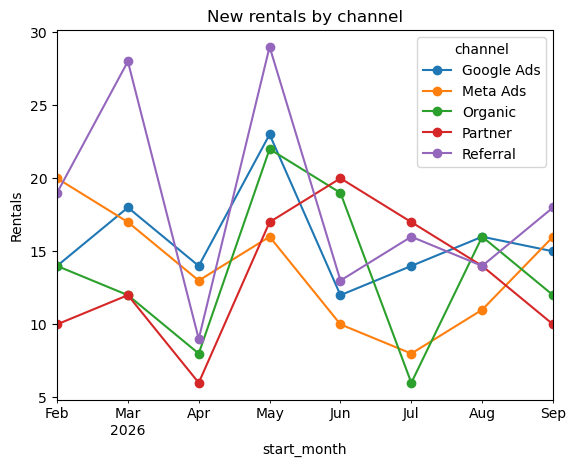

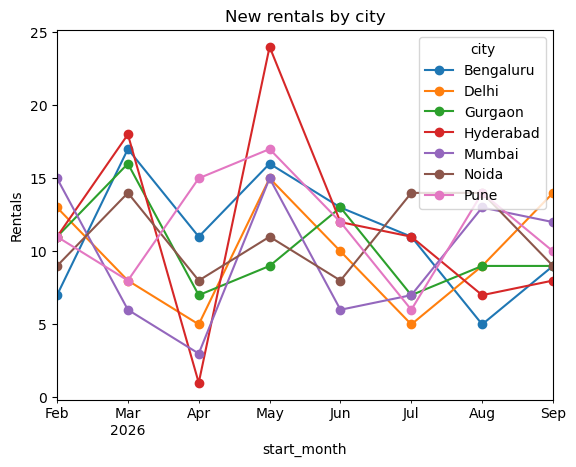

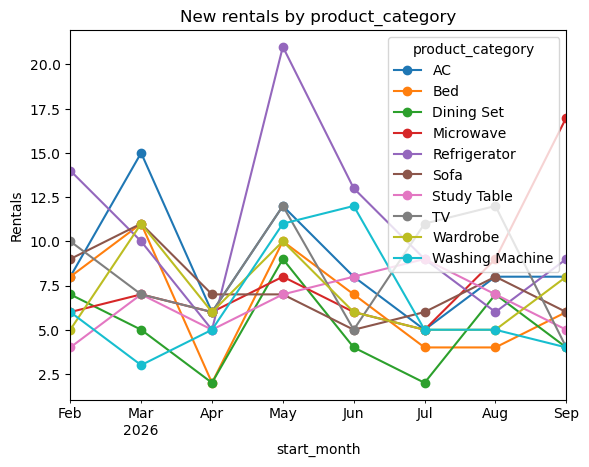

In [8]:
for seg in ["channel", "city", "product_category"]:
    pd.crosstab(df["start_month"], df[seg]).plot(marker="o", title=f"New rentals by {seg}")
    plt.ylabel("Rentals")
    plt.show()

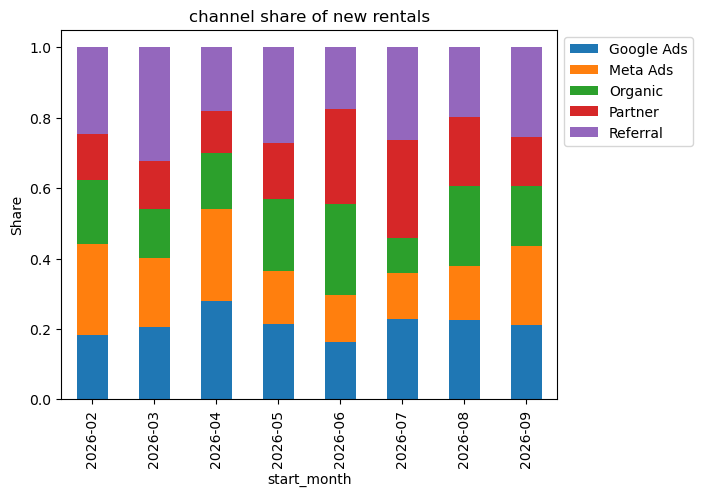

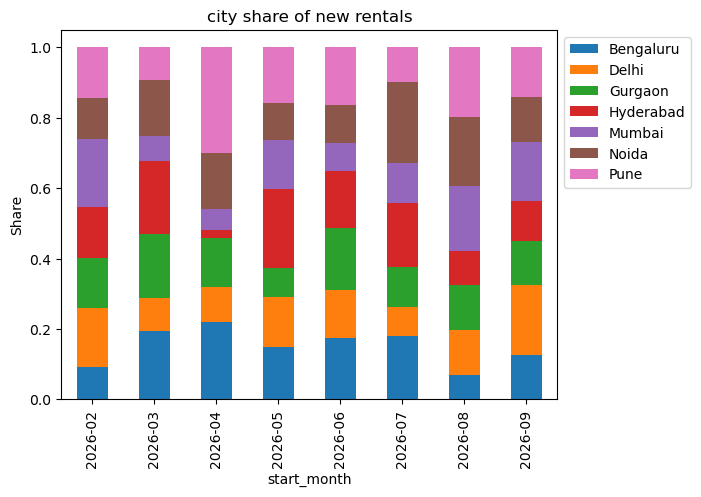

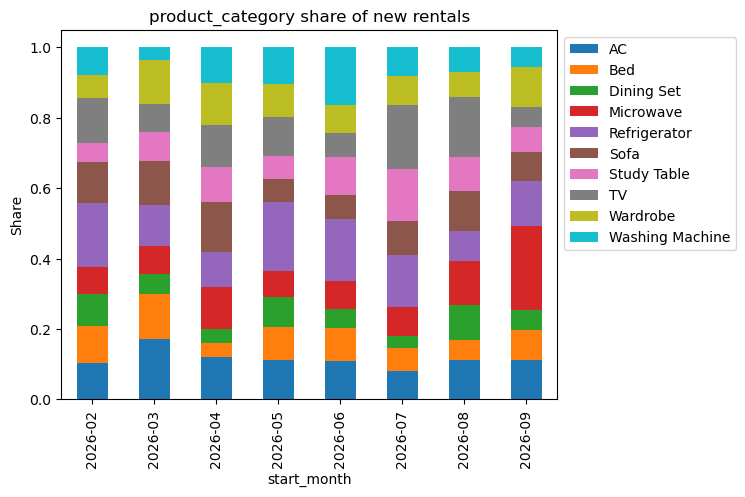

In [9]:
for seg in ["channel", "city", "product_category"]:
    pd.crosstab(df["start_month"], df[seg], normalize="index").plot(
        kind="bar", stacked=True, title=f"{seg} share of new rentals")
    plt.ylabel("Share")
    plt.legend(bbox_to_anchor=(1, 1))
    plt.show()

In [10]:
city_month = pd.crosstab(df["start_month"], df["city"])
print(city_month)

city         Bengaluru  Delhi  Gurgaon  Hyderabad  Mumbai  Noida  Pune
start_month                                                           
2026-02              7     13       11         11      15      9    11
2026-03             17      8       16         18       6     14     8
2026-04             11      5        7          1       3      8    15
2026-05             16     15        9         24      15     11    17
2026-06             13     10       13         12       6      8    12
2026-07             11      5        7         11       7     14     6
2026-08              5      9        9          7      13     14    14
2026-09              9     14        9          8      12      9    10


start_date
2026-02-08    3
2026-02-15    1
2026-02-22    3
2026-03-01    7
2026-03-08    5
2026-03-15    4
2026-03-22    2
2026-03-29    4
2026-04-05    0
2026-04-12    0
2026-04-19    0
2026-04-26    1
2026-05-03    0
2026-05-10    8
2026-05-17    5
2026-05-24    9
2026-05-31    2
2026-06-07    4
2026-06-14    4
2026-06-21    2
2026-06-28    2
2026-07-05    3
2026-07-12    4
2026-07-19    3
2026-07-26    0
2026-08-02    2
2026-08-09    4
2026-08-16    1
2026-08-23    1
2026-08-30    0
2026-09-06    2
2026-09-13    1
2026-09-20    2
2026-09-27    3
Freq: W-SUN, dtype: int64


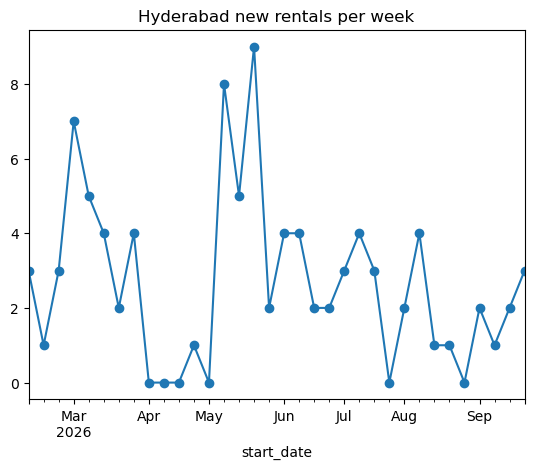

2026-04 2026-04-23 2026-04-23 1
2026-05 2026-05-04 2026-05-29 24


In [11]:
hyd = df[df["city"] == "Hyderabad"]

weekly = hyd.groupby(pd.Grouper(key="start_date", freq="W")).size()
print(weekly)
weekly.plot(marker="o", title="Hyderabad new rentals per week")
plt.show()

# first and last rental date in April and May
for m in ["2026-04", "2026-05"]:
    d = hyd[hyd["start_month"] == m]["start_date"]
    print(m, d.min().date(), d.max().date(), len(d))

In [12]:
h = hyd.groupby("start_month").size()
print(h)

normal = h.drop([pd.Period("2026-04"), pd.Period("2026-05")]).mean()
print("normal month:", round(normal, 1))
print("April + May:", h[pd.Period("2026-04")] + h[pd.Period("2026-05")], "vs 2 normal months:", round(2 * normal, 1))

start_month
2026-02    11
2026-03    18
2026-04     1
2026-05    24
2026-06    12
2026-07    11
2026-08     7
2026-09     8
Freq: M, dtype: int64
normal month: 11.2
April + May: 25 vs 2 normal months: 22.3


In [13]:
customers["signup_month"] = customers["signup_date"].dt.to_period("M")
signups = customers[customers["city"] == "Hyderabad"].groupby("signup_month").size()

print(pd.concat([signups, h], axis=1, keys=["signups", "rentals_started"]))

         signups  rentals_started
2026-01        7              NaN
2026-02       11             11.0
2026-03        5             18.0
2026-04        4              1.0
2026-05       18             24.0
2026-06        7             12.0
2026-07        9             11.0
2026-08        5              7.0
2026-09        3              8.0
